In [1]:
import logging
logging.captureWarnings(True)

In [2]:
import numpy as np
import networkx as nx

In [3]:
from multifractal_networks.mfng import MultifractalNetworkGenerator
from multifractal_networks.mfnf import MultifractalNetworkFitter

In [4]:
from multifractal_networks.utils.misc import recommend_N_for_k_range

# Generating a (starting) BA network

In [5]:
def generate_ba_graph(N, m=3, seed=42):
    """
    Generates a Barabási-Albert (BA) graph starting from a four-node clique.

    Parameters:
        N (int): Total number of nodes in the final network.
        m (int): Number of edges to attach from a new node to existing nodes.
        seed (int): Seed for reproducibility.

    Returns:
        G (networkx.Graph): Generated BA graph.
    """
    # Start with a 4-node fully connected graph (clique)
    initial_graph = nx.complete_graph(4)
    
    # Generate the BA graph
    G = nx.barabasi_albert_graph(N, m, seed=seed, initial_graph=initial_graph)
    return G

In [6]:
G_start = generate_ba_graph(1000)

In [7]:
G = G_start

In [8]:
G = nx.read_graphml("test_networks/ba_graph_1000.graphml")

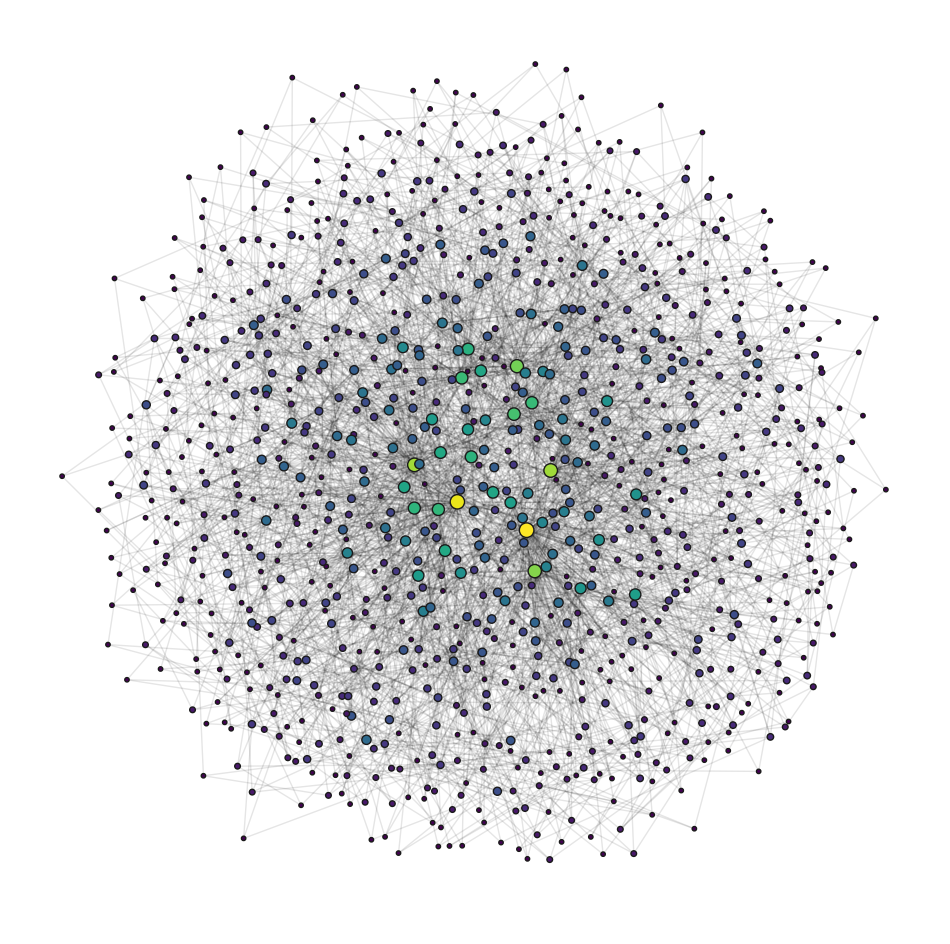

In [9]:
import matplotlib.pyplot as plt
from matplotlib.colors import Normalize, LogNorm

# Keep only the largest connected component
largest_cc = max(nx.connected_components(G), key=len)
G_largest = G.subgraph(largest_cc).copy()

# Sort nodes by degree (ascending), so high-degree nodes are processed last
sorted_nodes = sorted(G_largest.nodes(), key=lambda x: G_largest.degree[x], reverse=True)

# Relabel the graph nodes to ensure sorted order is reflected
mapping = {node: i for i, node in enumerate(sorted_nodes)}
G_largest = nx.relabel_nodes(G_largest, mapping)

# Recalculate node degrees (now sorted)
degree = dict(G_largest.degree())
nx.set_node_attributes(G_largest, degree, 'degree')

# Node size based on degree (logarithmic scaling)
degrees = np.array(list(degree.values()))
degrees += 1  # Avoid log(0) by shifting values
node_sizes = 10 + 100 * (np.log(degrees) - np.log(degrees.min())) / (
    np.log(degrees.max()) - np.log(degrees.min())
)

# Node color based on degree (logarithmic scaling)
cmap = plt.cm.viridis
node_colors = cmap((np.log(degrees) - np.log(degrees.min())) / (np.log(degrees.max()) - np.log(degrees.min())))

# Calculate edge betweenness centrality (for edge width and alpha)
edge_betweenness = nx.edge_betweenness_centrality(G_largest)
edge_widths = [1 + 7 * edge_betweenness[edge] for edge in G_largest.edges()]  # Scale edge widths for visibility
edge_alphas = [0.1 + 0.6 * edge_betweenness[edge] for edge in G_largest.edges()]  # Scale alpha from 0.1 to 1.0

# Positioning nodes using a force-directed layout
pos = nx.kamada_kawai_layout(G_largest)

# Plot the network
plt.figure(figsize=(12, 12))
# Draw edges with scaled widths and alphas
for edge, width, alpha in zip(G_largest.edges(), edge_widths, edge_alphas):
    nx.draw_networkx_edges(
        G_largest,
        pos,
        edgelist=[edge],
        width=width,
        alpha=alpha,
        edge_color="black",
    )

# Draw nodes with size and color mapped to attributes
nx.draw_networkx_nodes(
    G_largest,
    pos,
    node_size=node_sizes,
    node_color=node_colors,
    cmap=cmap,
    edgecolors='k',  # Add a border to nodes for clarity
)

# Remove labels and title for a cleaner plot
plt.gca().set_facecolor("black")

# Hide axes for cleaner visualization
plt.axis('off')
plt.savefig('./figures/ba_graph_1000_layout.pdf', dpi = 1000, bbox_inches='tight')
plt.show()

In [13]:
nx.write_graphml(G, "test_networks/ba_graph_1000.graphml")

In [11]:
2 * G.number_of_edges() / G.number_of_nodes()

5.988

# Init Fitter

In [5]:
G = nx.read_graphml("test_networks/ba_graph_1000.graphml")

In [6]:
# 2 * G.number_of_edges() / G.number_of_nodes()

In [7]:
for m_size in [2,3,5,6,7]:
    print(m_size,' k_max: ',int(np.log(len(G))/np.log(m_size))+1)

2  k_max:  10
3  k_max:  7
5  k_max:  5
6  k_max:  4
7  k_max:  4


In [8]:
mfnf = MultifractalNetworkFitter(
    G,                                   
    motifs = [
        {'name': 'four_chain', 'matrix': np.array([[0, 1, 0, 0],[1, 0, 1, 0],[0, 1, 0, 1],[0, 0, 1, 0]])},
        {'name': 'three_loop_out', 'matrix': np.array([[0, 1, 1, 1],[1, 0, 1, 0],[1, 1, 0, 0],[1, 0, 0, 0]])},
        {'name': 'four_loop', 'matrix': np.array([[0, 1, 0, 1],[1, 0, 1, 0],[0, 1, 0, 1],[1, 0, 1, 0]])},
        {'name': 'four_semi_clique', 'matrix': np.array([[0, 1, 1, 1],[1, 0, 0, 1],[1, 0, 0, 1],[1, 1, 1, 0]])},
    ],
    sampling_ratios = {
        3: 0.01,
        4: 0.0001
    },
    motif_analyzer_args = {'exact': True, 'bootstrap_iters': None, 'ci': None},
    population_size = 100,
    weights = {
        'rho':9,
        'deg_nn':0,
        'motifs':1,
        'edge':9
    }
)

Measuring graph properties...
Degree distribution...
Degree correlations...
Motifs...
Checking compatibility with 4 user-provided motifs.
Adding custom motif 'four_chain'.
Adding custom motif 'three_loop_out'.
Adding custom motif 'four_loop'.
Adding custom motif 'four_semi_clique'.
Counting motifs of size 3... grab a tea or watch a movie, this might take a while.
Motif counting finished in 0:00:00.246943
Counting motifs of size 4... grab a tea or watch a movie, this might take a while.
Motif counting finished in 0:00:04.098895


In [9]:
mfnf.motifs

[{'name': 'edge',
  'matrix': array([[0, 1],
         [1, 0]]),
  'size': 2,
  'count': 2994},
 {'name': 'wedge',
  'matrix': array([[0, 1, 1],
         [1, 0, 0],
         [1, 0, 0]]),
  'size': 3,
  'count': 44481},
 {'name': 'triangle',
  'matrix': array([[0, 1, 1],
         [1, 0, 1],
         [1, 1, 0]]),
  'size': 3,
  'count': 305},
 {'name': 'three_star',
  'matrix': array([[0, 1, 1, 1],
         [1, 0, 0, 0],
         [1, 0, 0, 0],
         [1, 0, 0, 0]]),
  'size': 4,
  'count': 799770},
 {'name': 'four_clique',
  'matrix': array([[0, 1, 1, 1],
         [1, 0, 1, 1],
         [1, 1, 0, 1],
         [1, 1, 1, 0]]),
  'size': 4,
  'count': 11},
 {'name': 'four_chain',
  'matrix': array([[0, 1, 0, 0],
         [1, 0, 1, 0],
         [0, 1, 0, 1],
         [0, 0, 1, 0]]),
  'size': 4,
  'count': 446141},
 {'name': 'three_loop_out',
  'matrix': array([[0, 1, 1, 1],
         [1, 0, 1, 0],
         [1, 1, 0, 0],
         [1, 0, 0, 0]]),
  'size': 4,
  'count': 35622},
 {'name': 'fou

# Grid Search

In [10]:
mfnf.find_m_k_P_l(
    m_k_dict = [{'m': 2,  'k': [1,11]},
                {'m': 3,  'k': [1,8]},
                {'m': 5,  'k': [1,6]},
                {'m': 7,  'k': [1,5]}],
    n_trials = None,
    P_init = 'm x m',
    l_init = 'dirichlet',
    verbose = False,
    grid_search = True,
    optimize_for = 'kl_energy'
)

[I 2025-01-23 15:23:58,769] A new study created in memory with name: no-name-0cd2cd9f-1eb0-493d-a2c6-63a08d526d78


Grid Search requires 10 trials...


[I 2025-01-23 15:24:12,673] Trial 0 finished with value: 6.25677180183269 and parameters: {'m': 2, 'k': 3}. Best is trial 0 with value: 6.25677180183269.
[I 2025-01-23 15:24:43,726] Trial 1 finished with value: 7.770742007530711 and parameters: {'m': 2, 'k': 9}. Best is trial 0 with value: 6.25677180183269.
[I 2025-01-23 15:24:58,909] Trial 2 finished with value: 6.8075922139125025 and parameters: {'m': 2, 'k': 5}. Best is trial 0 with value: 6.25677180183269.
[I 2025-01-23 15:26:02,474] Trial 3 finished with value: 7.2116142970441155 and parameters: {'m': 2, 'k': 10}. Best is trial 0 with value: 6.25677180183269.
[I 2025-01-23 15:26:15,839] Trial 4 finished with value: 5.53452367589123 and parameters: {'m': 2, 'k': 2}. Best is trial 4 with value: 5.53452367589123.
[I 2025-01-23 15:26:32,245] Trial 5 finished with value: 7.363413584594811 and parameters: {'m': 2, 'k': 7}. Best is trial 4 with value: 5.53452367589123.
[I 2025-01-23 15:26:50,943] Trial 6 finished with value: 7.5820011256

Grid Search requires 7 trials...


[I 2025-01-23 15:36:09,326] Trial 0 finished with value: 6.106450721400854 and parameters: {'m': 3, 'k': 7}. Best is trial 0 with value: 6.106450721400854.
[I 2025-01-23 15:36:41,428] Trial 1 finished with value: 4.424518767032782 and parameters: {'m': 3, 'k': 3}. Best is trial 1 with value: 4.424518767032782.
[I 2025-01-23 15:37:10,149] Trial 2 finished with value: 3.9929029828201585 and parameters: {'m': 3, 'k': 2}. Best is trial 2 with value: 3.9929029828201585.
[I 2025-01-23 15:37:46,756] Trial 3 finished with value: 5.2549437002174075 and parameters: {'m': 3, 'k': 4}. Best is trial 2 with value: 3.9929029828201585.
[I 2025-01-23 15:38:17,751] Trial 4 finished with value: 4.477283752807958 and parameters: {'m': 3, 'k': 1}. Best is trial 2 with value: 3.9929029828201585.
[I 2025-01-23 15:39:44,786] Trial 5 finished with value: 5.620473919959684 and parameters: {'m': 3, 'k': 6}. Best is trial 2 with value: 3.9929029828201585.
[I 2025-01-23 15:40:28,139] Trial 6 finished with value: 6

Grid Search requires 5 trials...


[I 2025-01-23 15:42:00,233] Trial 0 finished with value: 3.7774229657127445 and parameters: {'m': 5, 'k': 3}. Best is trial 0 with value: 3.7774229657127445.
[I 2025-01-23 15:43:06,353] Trial 1 finished with value: 3.2327426823872174 and parameters: {'m': 5, 'k': 1}. Best is trial 1 with value: 3.2327426823872174.
[I 2025-01-23 15:44:32,538] Trial 2 finished with value: 3.9446669204753886 and parameters: {'m': 5, 'k': 2}. Best is trial 1 with value: 3.2327426823872174.
[I 2025-01-23 15:47:33,837] Trial 3 finished with value: 5.179452132223604 and parameters: {'m': 5, 'k': 4}. Best is trial 1 with value: 3.2327426823872174.
[I 2025-01-23 16:26:24,375] Trial 4 finished with value: 5.759457273321196 and parameters: {'m': 5, 'k': 5}. Best is trial 1 with value: 3.2327426823872174.
[I 2025-01-23 16:26:24,376] A new study created in memory with name: no-name-45ead45a-e6e2-47d3-b2e9-511fb2d17e53


Grid Search requires 4 trials...


[I 2025-01-23 16:30:20,480] Trial 0 finished with value: 3.714349405735621 and parameters: {'m': 7, 'k': 3}. Best is trial 0 with value: 3.714349405735621.
[I 2025-01-23 17:12:02,342] Trial 1 finished with value: 5.17075157534673 and parameters: {'m': 7, 'k': 4}. Best is trial 0 with value: 3.714349405735621.
[I 2025-01-23 17:14:58,489] Trial 2 finished with value: 3.705782254875049 and parameters: {'m': 7, 'k': 2}. Best is trial 2 with value: 3.705782254875049.
[I 2025-01-23 17:16:58,396] Trial 3 finished with value: 3.3026035504738482 and parameters: {'m': 7, 'k': 1}. Best is trial 3 with value: 3.3026035504738482.


Best parameters:  {'m': 5, 'k': 1}
Best energy:  5.842454265505048
Best KL-divergence:  0.2993525736485183
Best KLD augumented energy: 3.2327426823872174
Best P matrix:
 [[3.36779637e-03 5.91114379e-03 3.10600796e-02 6.88325070e-02
  1.07827878e-01]
 [5.91114379e-03 1.16728196e-01 0.00000000e+00 1.87350135e-16
  0.00000000e+00]
 [3.10600796e-02 0.00000000e+00 4.56949612e-02 7.90095704e-03
  6.54872620e-01]
 [6.88325070e-02 1.87350135e-16 7.90095704e-03 3.25852185e-01
  6.27202307e-01]
 [1.07827878e-01 0.00000000e+00 6.54872620e-01 6.27202307e-01
  5.17534931e-01]]
Best l vector:
 [0.9164448  0.05556873 0.02236277 0.00381679 0.00180691]


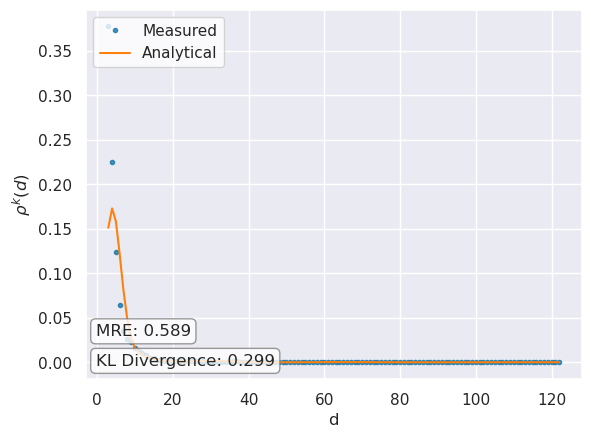

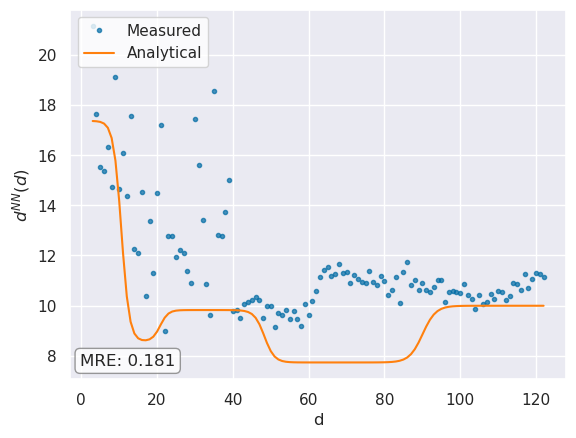

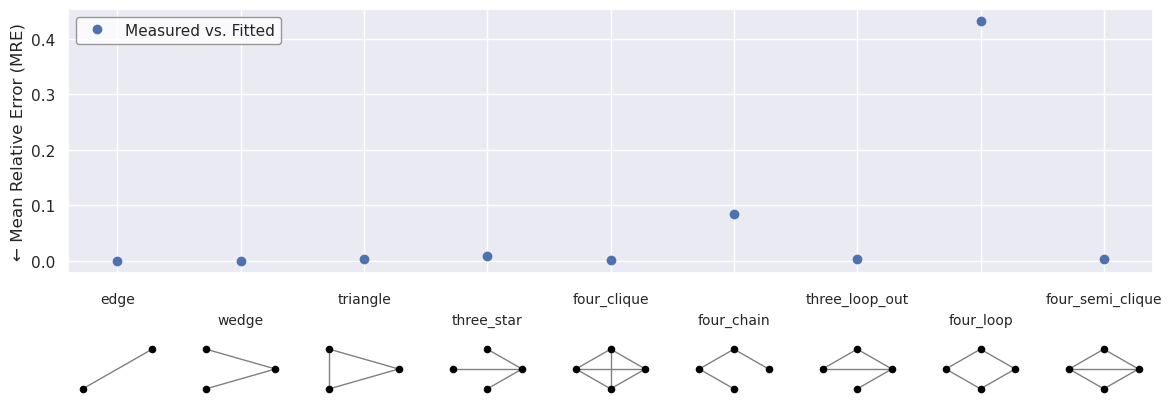

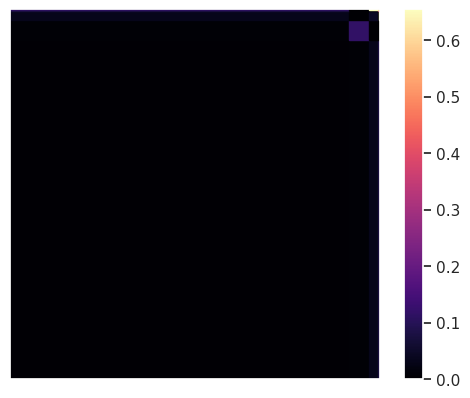

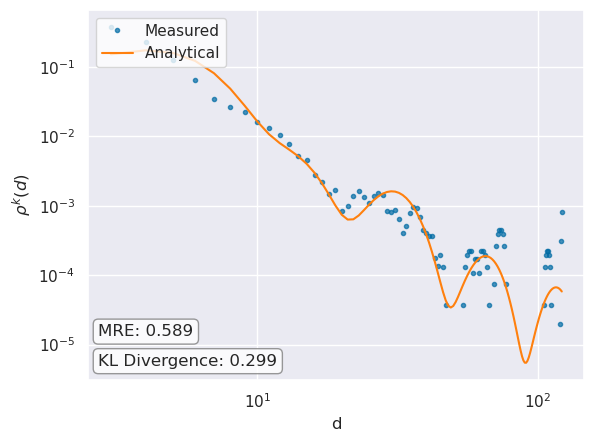

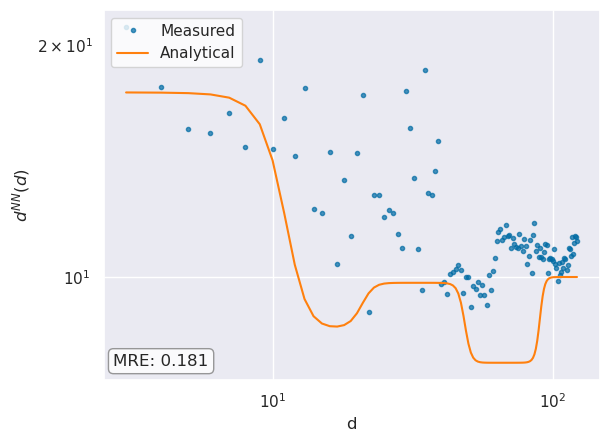

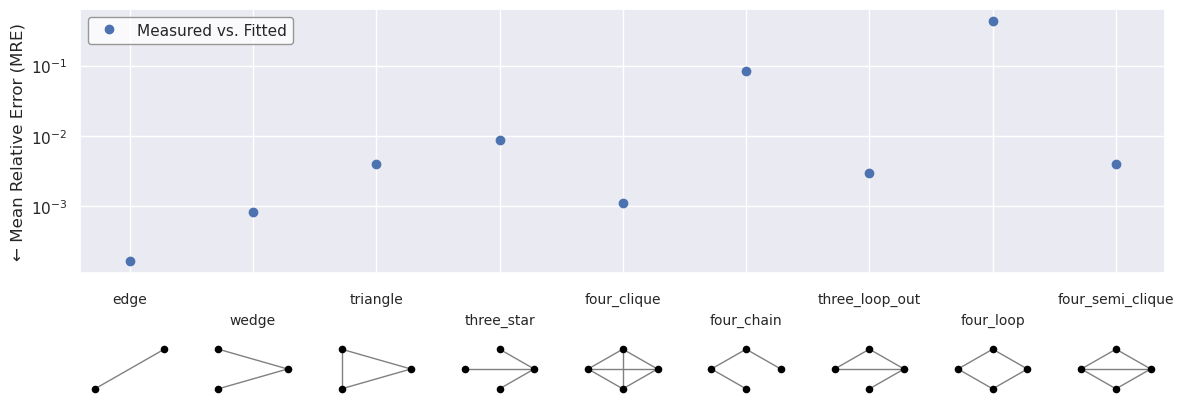

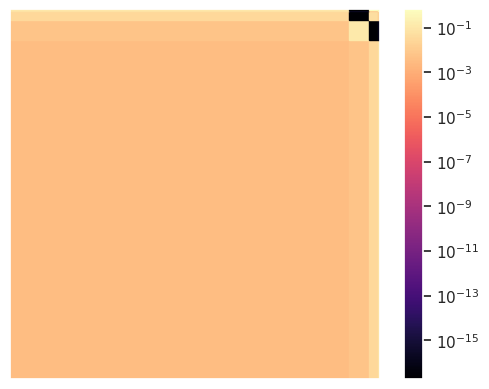

In [11]:
mfnf.plot_P_l_result(
    log_scale = False,
    grid = False,
    display_mre = True,
    display_kld = True,
    plot_cumulative_error = False,
    #filename = "figures/ba_graph_1000_plot.pdf"
)
mfnf.plot_P_l_result(
    log_scale = True,
    grid = False,
    display_mre = True,
    display_kld = True,
    plot_cumulative_error = False,
    #filename = "figures/ba_graph_1000_log_plot.pdf"
)

#### Looking at 'second best' m-k pairs from the grid search

Energy: 5.629435223342379
KL-divergence: 0.29873054080398737
KLD augumented energy: 3.3061771151642994


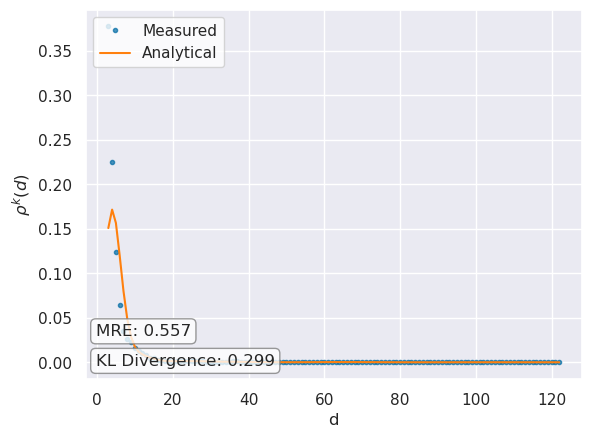

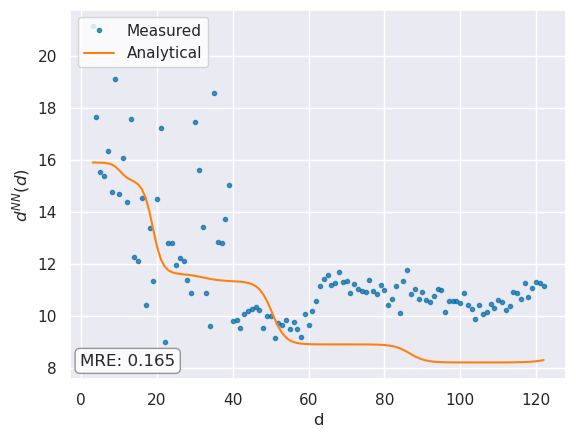

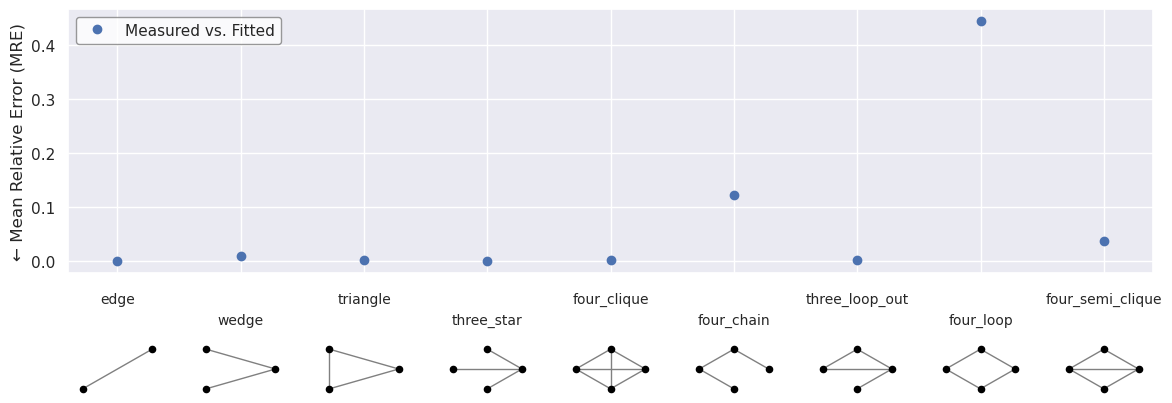

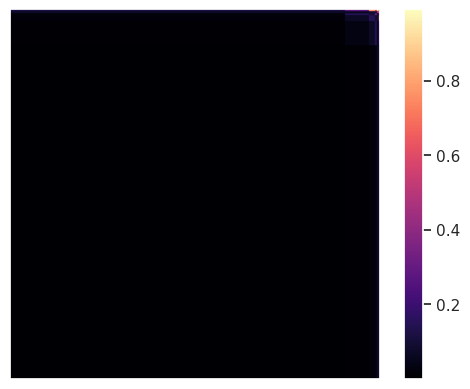

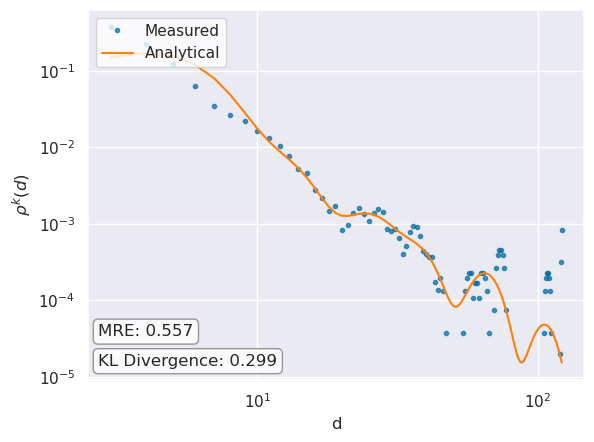

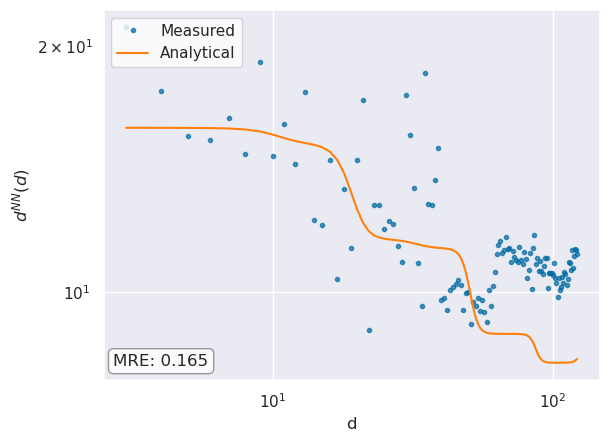

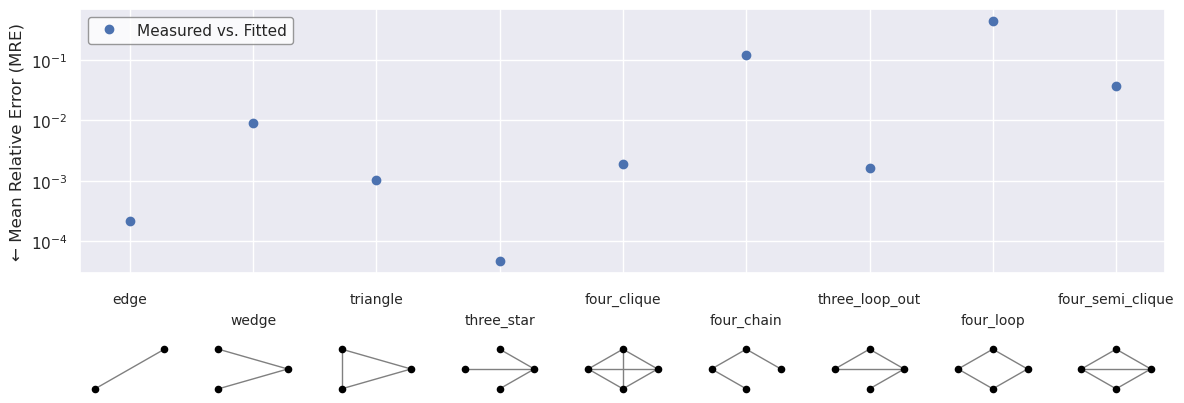

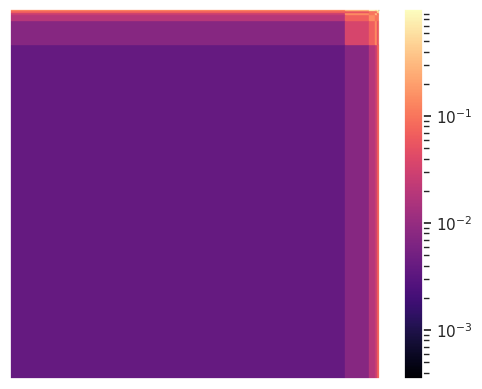

In [12]:
mfnf.find_P_l(m = 7, k = 1, one_shot=True)
mfnf.plot_P_l_result(
    log_scale = False,
    grid = False,
    display_mre = True,
    display_kld = True,
    plot_cumulative_error = False,
    #filename = "figures/ba_graph_1000_plot.pdf"
)
mfnf.plot_P_l_result(
    log_scale = True,
    grid = False,
    display_mre = True,
    display_kld = True,
    plot_cumulative_error = False,
    #filename = "figures/ba_graph_1000_log_plot.pdf"
)

# Bootstrapping Stability

In [15]:
mfnf.find_P_l(m = 5, k = 1, one_shot=True)

Energy: 5.8316197631440865
KL-divergence: 0.29421287998416085
KLD augumented energy: 3.358674818485681


In [18]:
mfnf.bootstrap_P_l_stability(
    P_init = 'm x m',
    l_init = 'dirichlet',
    verbose = True,
    resample_size = mfnf.population_size,
    ci = 0.95,
    medoid = 'mean'
)

Gathering statistics (30 runs)...


100%|██████████| 30/30 [33:31<00:00, 67.06s/it]

Bootstrapping: Resampling 100 times...


Bootstrapping finished in 0:00:00.298903
Energy = 5.96 (5.87, 6.02)
l = [0.93 (0.80, 0.96), 0.05 (0.02, 0.17), 0.02 (0.01, 0.03), 0.00 (0.00, 0.01), 0.00 (0.00, 0.00)]
P = [
[0.00 (0.00, 0.00), 0.01 (0.00, 0.02), 0.03 (0.02, 0.03), 0.06 (0.05, 0.08), 0.10 (0.08, 0.17)],

[0.01 (0.00, 0.02), 0.12 (0.00, 0.28), 0.04 (0.00, 0.17), 0.10 (0.00, 0.35), 0.25 (0.00, 1.00)],

[0.03 (0.02, 0.03), 0.04 (0.00, 0.17), 0.13 (0.00, 0.35), 0.13 (0.01, 0.32), 0.42 (0.10, 1.00)],

[0.06 (0.05, 0.08), 0.10 (0.00, 0.35), 0.13 (0.01, 0.32), 0.24 (0.00, 0.58), 0.74 (0.18, 1.00)],

[0.10 (0.08, 0.17), 0.25 (0.00, 1.00), 0.42 (0.10, 1.00), 0.74 (0.18, 1.00), 0.43 (0.00, 0.87)]
]


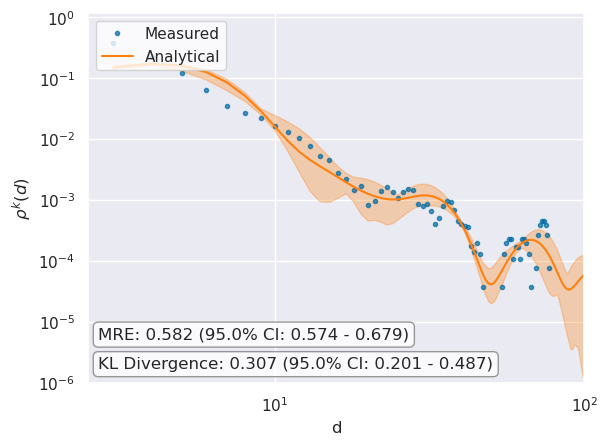

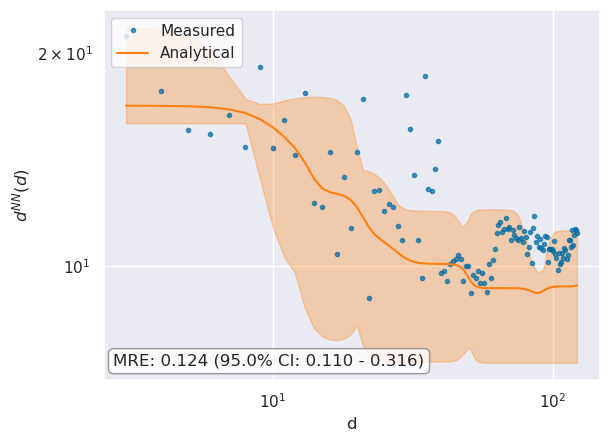

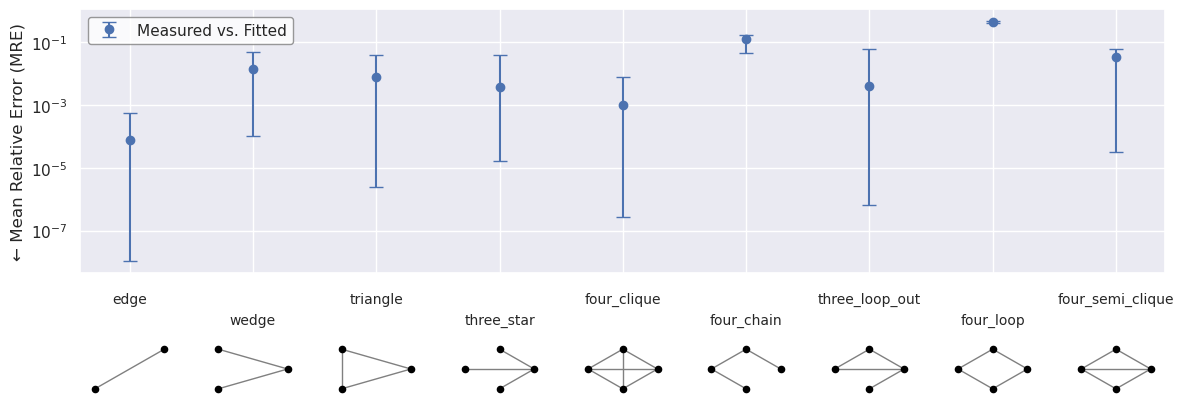

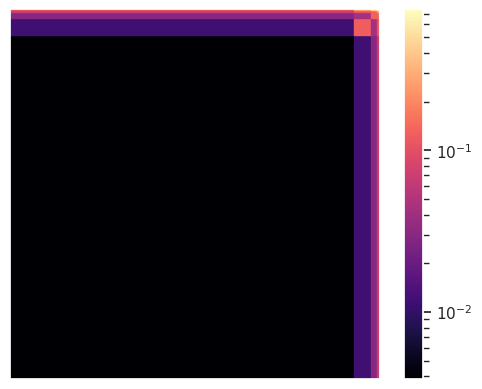

In [24]:
mfnf.plot_P_l_result(
    log_scale = True,
    grid = False,
    display_mre = True,
    display_kld = True,
    plot_cumulative_error = False,
    xlim = [0,100],
    ylim = [1e-6,0],
    filename = "figures/ba_graph_1000_log_plot_bootstrap.pdf"
)

# Scaling the network

In [25]:
P = mfnf.P
l = mfnf.l
k_1k = mfnf.k

In [26]:
recommend_N_for_k_range(
    P = P,
    l = l,
    k = k_1k,
    avg_degree = 2 * G.number_of_edges() / G.number_of_nodes(),
    k_limit = 3)

{2: 147618, 3: 23177788}

## generating a new BA graph

In [29]:
G_new = generate_ba_graph(147618)

In [30]:
G = G_new

In [31]:
nx.write_graphml(G, "test_networks/ba_graph_147618.graphml")

## Checking against the measure

In [32]:
mfnf_no_fit = MultifractalNetworkFitter(
    G,                                   
    motifs = [
        {'name': 'four_chain', 'matrix': np.array([[0, 1, 0, 0],[1, 0, 1, 0],[0, 1, 0, 1],[0, 0, 1, 0]])},
        {'name': 'three_loop_out', 'matrix': np.array([[0, 1, 1, 1],[1, 0, 1, 0],[1, 1, 0, 0],[1, 0, 0, 0]])},
        {'name': 'four_loop', 'matrix': np.array([[0, 1, 0, 1],[1, 0, 1, 0],[0, 1, 0, 1],[1, 0, 1, 0]])},
        {'name': 'four_semi_clique', 'matrix': np.array([[0, 1, 1, 1],[1, 0, 0, 1],[1, 0, 0, 1],[1, 1, 1, 0]])},
    ],
    sampling_ratios = {
        3: 0.01,
        4: 0.0001
    },
    motif_analyzer_args = {'exact': True, 'bootstrap_iters': None, 'ci': None},
    population_size = 100,
    weights = {
        'rho':9,
        'deg_nn':0,
        'motifs':1,
        'edge':9
    }
)

Measuring graph properties...
Degree distribution...
Degree correlations...
Motifs...
Checking compatibility with 4 user-provided motifs.
Adding custom motif 'four_chain'.
Adding custom motif 'three_loop_out'.
Adding custom motif 'four_loop'.
Adding custom motif 'four_semi_clique'.
Counting motifs of size 3... grab a tea or watch a movie, this might take a while.
Motif counting finished in 0:00:49.547163
Counting motifs of size 4... grab a tea or watch a movie, this might take a while.
Motif counting finished in 4:39:38.297740


In [33]:
mfnf_no_fit.P = P
mfnf_no_fit.l = l
mfnf_no_fit.k = 2

In [34]:
mfnf_no_fit._calculate_metrics()

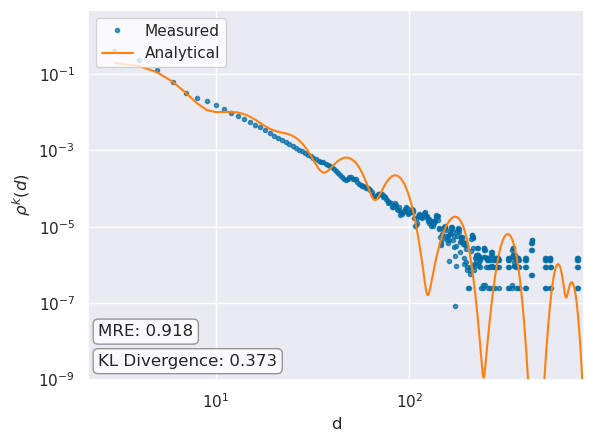

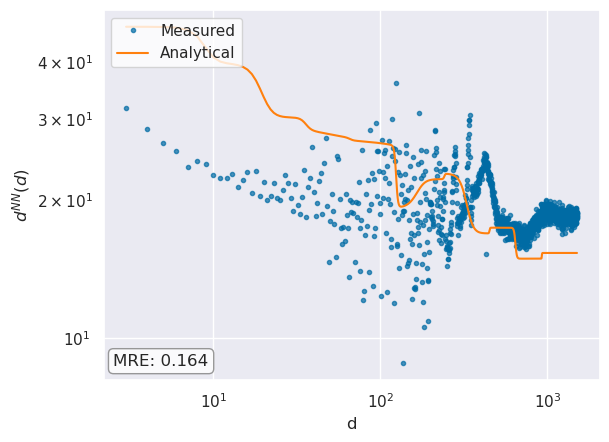

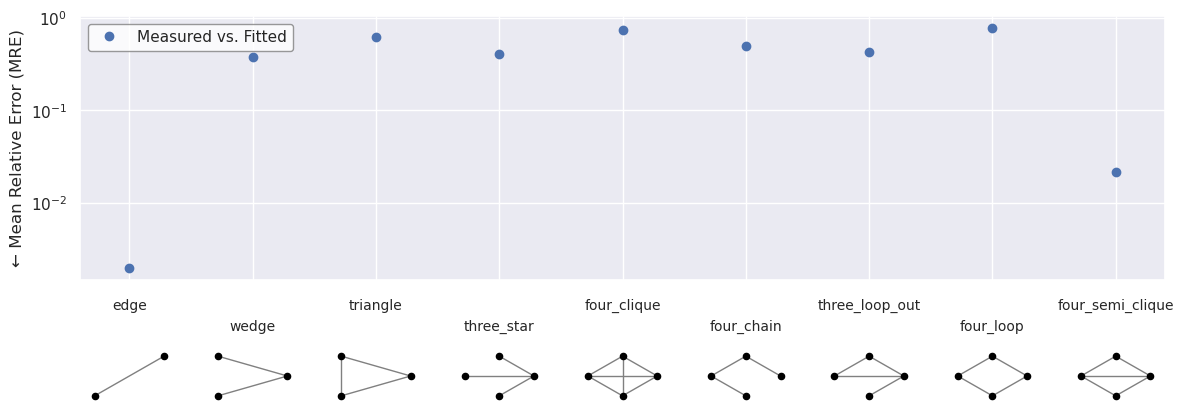

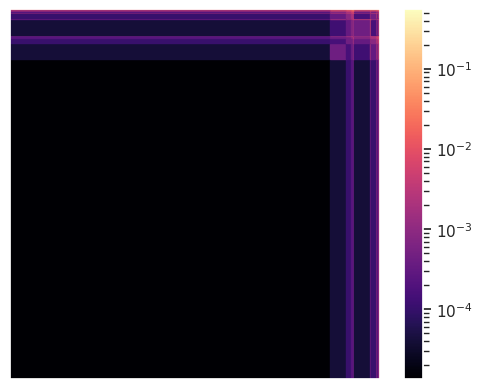

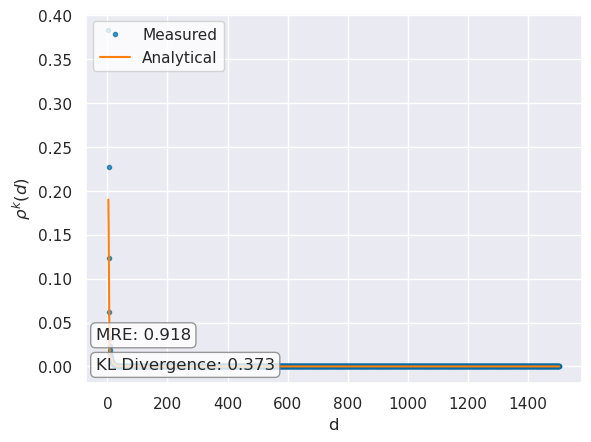

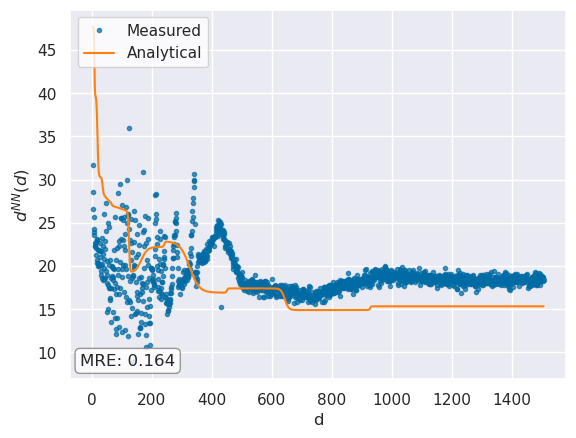

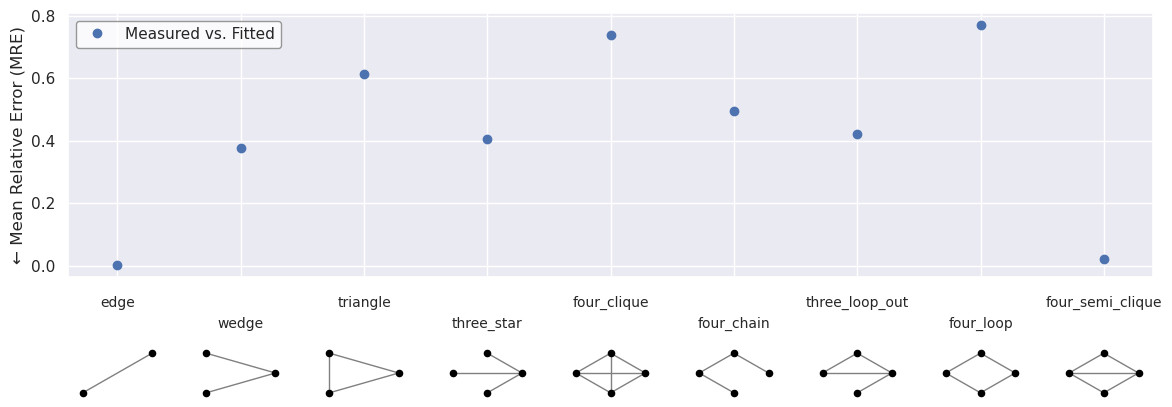

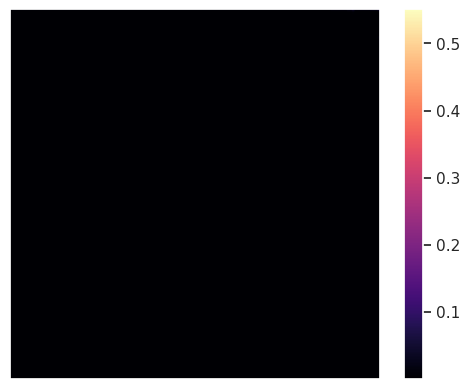

In [44]:
mfnf_no_fit.plot_P_l_result(
    log_scale = True,
    grid = False,
    display_mre = True,
    display_kld = True,
    plot_cumulative_error = False,
    xlim = [0,800],
    ylim = [1e-9,0],
    filename = "figures/ba_graph_147618_log_plot.pdf"
)
mfnf_no_fit.plot_P_l_result(
    log_scale = False,
    grid = False,
    display_mre = True,
    display_kld = True,
    plot_cumulative_error = False,
    #xlim = [0,800],
    #ylim = [1e-9,0],
    filename = "figures/ba_graph_147618_plot.pdf"
)

In [36]:
mfnf_no_fit.save_motifs("test_networks/ba_graph_147618_motifs.pkl")